In [1]:
from google.colab import files
uploaded = files.upload()


Saving Telco-Customer-Churn - Telco-Customer-Churn.csv.csv to Telco-Customer-Churn - Telco-Customer-Churn.csv.csv


In [2]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("File:", filename)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


File: Telco-Customer-Churn - Telco-Customer-Churn.csv.csv
Shape: (7043, 21)
Columns: ['customer id', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customer id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Missing values by column:")
display(df.isna().sum()[df.isna().sum() > 0])

print("Churn counts:")
display(df["Churn"].value_counts())

print("Churn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

Missing values by column:


,0
TotalCharges,11


Churn counts:


,count
Churn,
No,5174
Yes,1869


Churn percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [4]:
missing_rows = df.loc[
    df["TotalCharges"].isna(),
    ["customer id", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

display(missing_rows)

,customer id,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [5]:
df_clean = df.copy()
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing TotalCharges after cleaning:", df_clean["TotalCharges"].isna().sum())
print("Cleaned TotalCharges type:", df_clean["TotalCharges"].dtype)

Missing TotalCharges after cleaning: 0
Cleaned TotalCharges type: float64


In [6]:
df_clean["ChurnFlag"] = (df_clean["Churn"] == "Yes").astype(int)

contract_summary = df_clean.groupby("Contract").agg(
    customers=("ChurnFlag", "size"),
    churned_customers=("ChurnFlag", "sum"),
    churn_rate=("ChurnFlag", "mean")
)

contract_summary["churn_rate"] = (contract_summary["churn_rate"] * 100).round(2)
display(contract_summary)

,customers,churned_customers,churn_rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


In [7]:
for feature in ["TechSupport", "StreamingTV", "DeviceProtection"]:
    summary = df_clean.groupby(feature).agg(
        customers=("ChurnFlag", "size"),
        churn_rate=("ChurnFlag", "mean")
    )
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(2)

    print(f"\nChurn by {feature}:")
    display(summary)


Churn by TechSupport:


,customers,churn_rate
TechSupport,,
No,3473,41.64
No internet service,1526,7.40
Yes,2044,15.17



Churn by StreamingTV:


,customers,churn_rate
StreamingTV,,
No,2810,33.52
No internet service,1526,7.40
Yes,2707,30.07



Churn by DeviceProtection:


,customers,churn_rate
DeviceProtection,,
No,3095,39.13
No internet service,1526,7.40
Yes,2422,22.50


In [8]:
display(
    df_clean.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .agg(["mean", "median"])
    .round(2)
)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

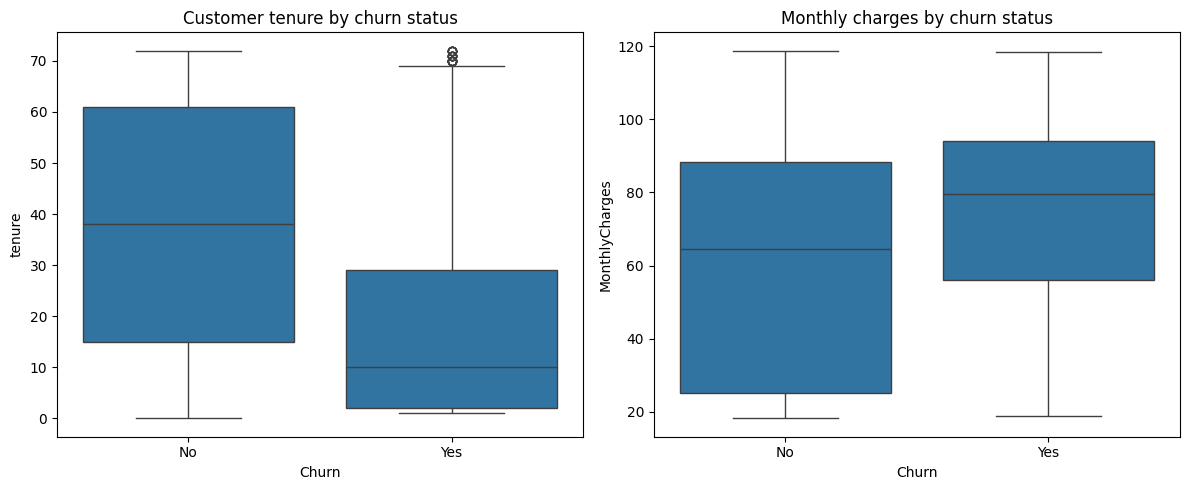

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Customer tenure by churn status")
axes[0].set_xlabel("Churn")

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly charges by churn status")
axes[1].set_xlabel("Churn")

plt.tight_layout()
plt.show()

In [10]:
import sqlite3

conn = sqlite3.connect(":memory:")
df_clean.to_sql("customers", conn, index=False, if_exists="replace")

query = """
SELECT
    Contract,
    COUNT(*) AS customers,
    SUM(ChurnFlag) AS churned_customers,
    ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC;
"""

sql_contract = pd.read_sql_query(query, conn)
display(sql_contract)

,Contract,customers,churned_customers,churn_rate_pct
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [11]:
query = """
SELECT
    TechSupport,
    COUNT(*) AS customers,
    SUM(ChurnFlag) AS churned_customers,
    ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY TechSupport
ORDER BY churn_rate_pct DESC;
"""

sql_support = pd.read_sql_query(query, conn)
display(sql_support)

,TechSupport,customers,churned_customers,churn_rate_pct
0,No,3473,1446,41.64
1,Yes,2044,310,15.17
2,No internet service,1526,113,7.40


In [12]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["customer id", "Churn", "ChurnFlag"])
y = df_clean["ChurnFlag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Churn rate in training data:", round(y_train.mean() * 100, 2), "%")
print("Churn rate in test data:", round(y_test.mean() * 100, 2), "%")

Training rows: 5634
Test rows: 1409
Churn rate in training data: 26.54 %
Churn rate in test data: 26.54 %


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Confusion matrix (actual rows; predicted columns):")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Confusion matrix (actual rows; predicted columns):
[[926 109]
 [165 209]]

Classification report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.842


In [14]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.30, 0.40, 0.50, 0.60]:
    predictions = (y_prob >= threshold).astype(int)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)

    print(
        f"Threshold {threshold:.2f} | "
        f"Precision: {precision:.2f} | Recall: {recall:.2f}"
    )

Threshold 0.30 | Precision: 0.52 | Recall: 0.75
Threshold 0.40 | Precision: 0.57 | Recall: 0.67
Threshold 0.50 | Precision: 0.66 | Recall: 0.56
Threshold 0.60 | Precision: 0.72 | Recall: 0.40


In [15]:
from sklearn.metrics import confusion_matrix

threshold = 0.40
y_pred_40 = (y_prob >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_40).ravel()

print("Test customers flagged:", tp + fp)
print("Churners correctly flagged:", tp)
print("Flagged customers who stayed:", fp)
print("Churners missed:", fn)

Test customers flagged: 440
Churners correctly flagged: 250
Flagged customers who stayed: 190
Churners missed: 124


In [16]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "average_auc_drop": importance.importances_mean,
    "variation": importance.importances_std
}).sort_values("average_auc_drop", ascending=False)

display(importance_df)

,feature,average_auc_drop,variation
4,tenure,0.172368,0.005056
7,InternetService,0.038716,0.010513
14,Contract,0.032782,0.003398
17,MonthlyCharges,0.030431,0.006725
18,TotalCharges,0.014275,0.002271
8,OnlineSecurity,0.004060,0.001778
11,TechSupport,0.003870,0.001038
13,StreamingMovies,0.003789,0.001924
12,StreamingTV,0.003239,0.002208
16,PaymentMethod,0.003204,0.001518


In [17]:
from google.colab import files

df_clean.to_csv("telco_churn_cleaned.csv", index=False)
files.download("telco_churn_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>